# PH⁰ dimension: estimator and validation

Re-implementation of Algorithm 1 of Birdal, Lou, Guibas, Şimşekli, *Intrinsic Dimension, Persistent Homology and Generalization in Neural Networks* (NeurIPS 2021), and its validation on point clouds whose dimension is known.

1. **Sets of known dimension**: circle, square, a square hidden in ℝ¹⁰⁰, cube, Sierpinski triangle; MST lifetimes vs Ripser.
2. **β-stable Lévy paths** in ℝ¹²⁸, whose dimension is the tail index β: Fig. 6 and Fig. 7 of the paper, and the effect of the number of points.

The code is in the `phdim` package; this notebook only calls it. On Colab: run the setup cell first (it clones the repository and installs the package).

## Setup

In [9]:
import os

if os.path.basename(os.getcwd()) == "notebooks":  # running inside a local clone
    %cd ..
if not os.path.isdir("phdim"):  # on Colab: fetch the repository
    !git clone -q https://github.com/mahird3/phdim-generalization.git
    %cd phdim-generalization
%pip install -q -e ".[notebook]"

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for phdim (pyproject.toml) ... done


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from ripser import ripser

from phdim import distance_matrix, ph0_lifetimes, ph_dim, levy_increments, levy_path
from phdim.shapes import circle, cube, embed, sierpinski

Unit tests (about a minute):

In [11]:
!python -m pytest -q

.......................                                                  [100%]
23 passed in 33.17s


## 1. Sets of known dimension

Each set has 1000 points. A straight line in the log–log plot means the power law $E_1(k) \propto k^{m}$ holds; the dimension is $1/(1-m)$.

circle           truth 1.000   estimate 1.018   slope m = 0.017
square           truth 2.000   estimate 1.901   slope m = 0.474
square in R^100  truth 2.000   estimate 1.900   slope m = 0.474
cube             truth 3.000   estimate 2.834   slope m = 0.647
Sierpinski       truth 1.585   estimate 1.612   slope m = 0.380


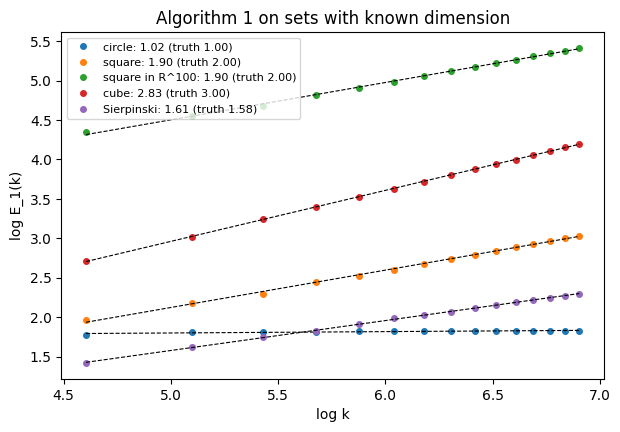

MST lifetimes == Ripser H0 deaths: True


In [12]:
rng = np.random.default_rng(0)
K = 1000
circ = circle(K, rng)
square = cube(K, 2, rng)
# name: (points, true dimension)
test_sets = {
    "circle": (circ, 1.0),
    "square": (square, 2.0),
    "square in R^100": (embed(square, 100, rng), 2.0),
    "cube": (cube(K, 3, rng), 3.0),
    "Sierpinski": (sierpinski(K, rng), np.log(3) / np.log(2)),
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, (X, truth) in test_sets.items():
    dim, c = ph_dim(X, n_repeats=3, return_curve=True)
    print(f"{name:16s} truth {truth:.3f}   estimate {dim:.3f}   slope m = {c['slope']:.3f}")
    x = np.log(c["k"])
    ax.plot(x, c["log_E"], "o", ms=4, label=f"{name}: {dim:.2f} (truth {truth:.2f})")
    ax.plot(x, c["slope"] * x + c["intercept"], "k--", lw=0.8)
ax.set_xlabel("log k")
ax.set_ylabel("log E_1(k)")
ax.set_title("Algorithm 1 on sets with known dimension")
ax.legend(fontsize=8)
plt.show()

# PH0 lifetimes from the MST must equal Ripser's finite H0 deaths
P = rng.random((200, 5))
h0 = ripser(P, maxdim=0)["dgms"][0]
deaths = np.sort(h0[np.isfinite(h0[:, 1]), 1])
print("MST lifetimes == Ripser H0 deaths:", np.allclose(deaths, np.sort(ph0_lifetimes(distance_matrix(P))), atol=1e-5))


## 2. β-stable Lévy paths

Paths of $K = 1000$ points in $d = 128$; the true dimension is β. Increments are $X = \sqrt{2A}\,G$ with $G \sim \mathcal N(0, I_d)$ and $A$ positive (β/2)-stable (Kanter's formula), so that $\mathbb E\, e^{i\langle w, X\rangle} = e^{-\|w\|^\beta}$.

beta 1.0:  E cos(wX) = [0.605 0.366 0.131]   theory [0.607 0.368 0.135]   OK
beta 1.5:  E cos(wX) = [0.701 0.367 0.061]   theory [0.702 0.368 0.059]   OK
beta 2.0:  E cos(wX) = [0.779 0.367 0.019]   theory [0.779 0.368 0.018]   OK


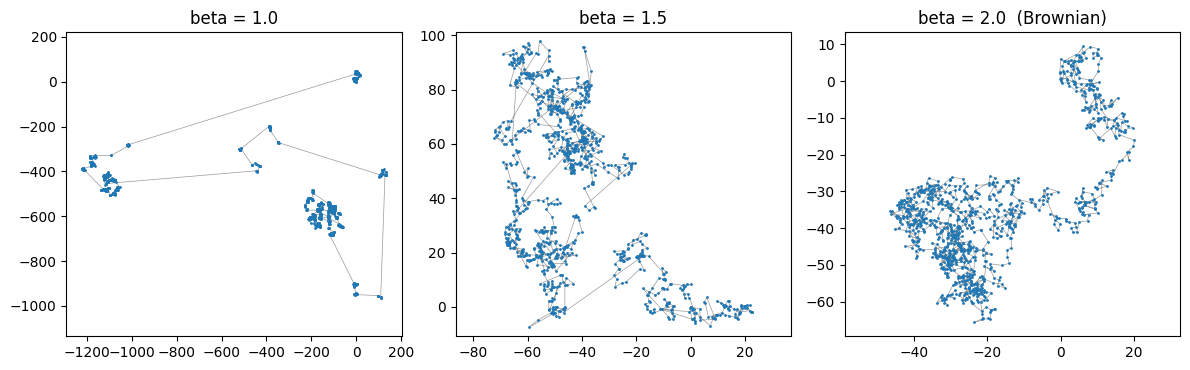

In [13]:
# Sampler check: the characteristic function of one coordinate must be exp(-|w|^beta)
rng = np.random.default_rng(1)
w = np.array([0.5, 1.0, 2.0])
sampler_ok = True
for beta in [1.0, 1.5, 2.0]:
    X = levy_increments(100_000, 1, beta, rng)[:, 0]
    emp, th = np.cos(np.outer(w, X)).mean(axis=1), np.exp(-w ** beta)
    ok = np.abs(emp - th).max() < 0.01
    sampler_ok &= ok
    print(f"beta {beta}:  E cos(wX) = {np.round(emp, 3)}   theory {np.round(th, 3)}   {'OK' if ok else 'FAIL'}")

# What the paths look like: first two of the 128 coordinates
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, beta in zip(axes, [1.0, 1.5, 2.0]):
    P = levy_path(1000, 128, beta, rng)
    ax.plot(P[:, 0], P[:, 1], "-", lw=0.5, color="0.6")
    ax.plot(P[:, 0], P[:, 1], ".", ms=2)
    ax.set_title(f"beta = {beta}" + ("  (Brownian)" if beta == 2 else ""))
    ax.set_aspect("equal", "datalim")
plt.tight_layout()
plt.show()

assert sampler_ok

### Fig. 6 and Fig. 7: estimate vs β, and the effect of α

3 paths per β. Each path's distance matrix is computed once and reused for every α. Takes about a minute.

102 s

alpha = 1:
  beta 1.0   estimate 1.19 ± 0.13   paths [1.05 1.37 1.17]
  beta 1.2   estimate 1.27 ± 0.16   paths [1.5  1.19 1.13]
  beta 1.4   estimate 1.61 ± 0.04   paths [1.56 1.66 1.6 ]
  beta 1.6   estimate 1.77 ± 0.04   paths [1.8  1.8  1.72]
  beta 1.8   estimate 1.95 ± 0.06   paths [1.91 2.03 1.91]
  beta 2.0   estimate 2.20 ± 0.01   paths [2.19 2.22 2.2 ]
  mean |estimate - beta| = 0.17
  increasing in beta: OK


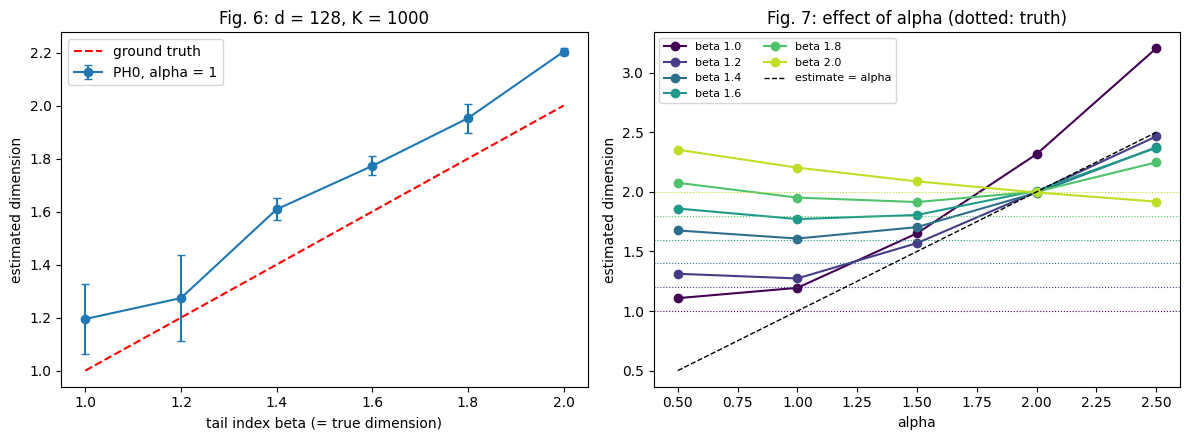

In [14]:
import time

d, K, n_paths = 128, 1000, 3
betas = np.round(np.arange(1.0, 2.01, 0.2), 1)
alphas = np.array([0.5, 1.0, 1.5, 2.0, 2.5])
rng = np.random.default_rng(2)

t0 = time.time()
est = np.empty((len(betas), n_paths, len(alphas)))  # [beta, path, alpha]
for i, beta in enumerate(betas):
    for j in range(n_paths):
        D = distance_matrix(levy_path(K, d, beta, rng))  # once per path, reused for every alpha
        for l, a in enumerate(alphas):
            est[i, j, l] = ph_dim(D=D, alpha=a, seed=j)
print(f"{time.time() - t0:.0f} s\n")

e1 = est[:, :, alphas == 1.0][:, :, 0]  # alpha = 1, shape [beta, path]
print("alpha = 1:")
for beta, row in zip(betas, e1):
    print(f"  beta {beta:.1f}   estimate {row.mean():.2f} ± {row.std():.2f}   paths {np.round(row, 2)}")
print(f"  mean |estimate - beta| = {np.abs(e1.mean(axis=1) - betas).mean():.2f}")
print("  increasing in beta:", "OK" if np.all(np.diff(e1.mean(axis=1)) > -0.05) else "NO")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.errorbar(betas, e1.mean(axis=1), yerr=e1.std(axis=1), fmt="o-", capsize=3, label="PH0, alpha = 1")
ax1.plot(betas, betas, "r--", label="ground truth")
ax1.set_xlabel("tail index beta (= true dimension)")
ax1.set_ylabel("estimated dimension")
ax1.set_title(f"Fig. 6: d = {d}, K = {K}")
ax1.legend()

colors = plt.cm.viridis(np.linspace(0, 0.9, len(betas)))
for beta, c, row in zip(betas, colors, est.mean(axis=1)):
    ax2.plot(alphas, row, "o-", color=c, label=f"beta {beta:.1f}")
    ax2.axhline(beta, color=c, ls=":", lw=0.8)
ax2.plot(alphas, alphas, "k--", lw=1, label="estimate = alpha")
ax2.set_xlabel("alpha")
ax2.set_ylabel("estimated dimension")
ax2.set_title("Fig. 7: effect of alpha (dotted: truth)")
ax2.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### Effect of the number of points K

Fig. 6 of the paper has one panel per K. K = 200 is the case that matters for step 3 (the last 200 iterates of training).

K =  200   1.0: 1.24   1.2: 1.34   1.4: 1.81   1.6: 1.92   1.8: 2.09   2.0: 2.29
K =  500   1.0: 1.40   1.2: 1.38   1.4: 1.49   1.6: 1.63   1.8: 2.05   2.0: 2.27
K = 1000   1.0: 1.28   1.2: 1.43   1.4: 1.58   1.6: 1.71   1.8: 2.02   2.0: 2.22
K = 1500   1.0: 1.17   1.2: 1.35   1.4: 1.60   1.6: 1.54   1.8: 2.01   2.0: 2.23


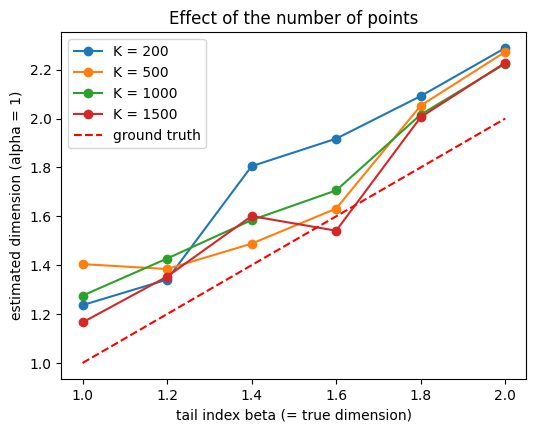

In [15]:
Ks = [200, 500, 1000, 1500]
rng = np.random.default_rng(3)

by_K = np.empty((len(Ks), len(betas)))
for i, K_ in enumerate(Ks):
    for j, beta in enumerate(betas):
        by_K[i, j] = np.mean([ph_dim(levy_path(K_, d, beta, rng), seed=s) for s in range(n_paths)])
    print(f"K = {K_:4d}   " + "   ".join(f"{b:.1f}: {e:.2f}" for b, e in zip(betas, by_K[i])))

fig, ax = plt.subplots(figsize=(6, 4.5))
for K_, row in zip(Ks, by_K):
    ax.plot(betas, row, "o-", label=f"K = {K_}")
ax.plot(betas, betas, "r--", label="ground truth")
ax.set_xlabel("tail index beta (= true dimension)")
ax.set_ylabel("estimated dimension (alpha = 1)")
ax.set_title("Effect of the number of points")
ax.legend()
plt.show()